# Thử nghiệm GARCH(1,1)

Notebook này huấn luyện mô hình GARCH với tham số cố định của dự án trên tập huấn luyện theo thời gian, rồi dự báo tại các mốc của tập xác thực và tập kiểm tra. Dữ liệu được dựng từ tệp CSV thô cục bộ đã cấu hình; không tải dữ liệu từ mạng. Nhãn là độ lệch chuẩn mẫu của lợi suất log trong năm phiên tiếp theo, tính theo điểm phần trăm. Căn bậc hai của phương sai có điều kiện trung bình qua nhiều bước là giá trị xấp xỉ cho nhãn này.

Chạy notebook từ thư mục gốc của kho mã hoặc từ thư mục `notebooks`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.pipeline.dataset import prepare_dataset, valid_history
from src.evaluation.regression import regression_metrics

config = load_config(ROOT / "config.yaml")
ticker = config["data"].get("ticker", "ACB")
dataset = prepare_dataset(ticker, config)
history = valid_history(dataset)
print(f"Mã cổ phiếu: {ticker} | nhãn: {dataset.target} | kỳ hạn: {dataset.horizon} phiên")
for name in ("train", "validation", "test"):
    part = getattr(dataset, name)
    print(f"{name:10s} {part.date.min().date()} -> {part.date.max().date()} | số mẫu={len(part)}")


Mã cổ phiếu: ACB | nhãn: target_volatility_5d | kỳ hạn: 5 phiên
train      2018-12-28 -> 2024-06-05 | số mẫu=1349
validation 2024-06-13 -> 2025-08-01 | số mẫu=285
test       2025-08-11 -> 2026-10-12 | số mẫu=291


## Huấn luyện mô hình cơ sở

Mô hình chỉ ước lượng tham số bằng lợi suất trong tập huấn luyện. Với mỗi mốc dự báo về sau, mô hình lọc các lợi suất đã quan sát đến ngày đó bằng tham số đã ước lượng.

In [2]:
from src.models.garch_model import GARCHModel

settings = config["models"]["garch"]
model = GARCHModel(
    horizon=dataset.horizon,
    mean=settings["mean"],
    distribution=settings["distribution"],
).fit(dataset.train)
print("Tham số ước lượng:", model.params)
print("Ngày cuối tập huấn luyện:", model.train_end.date())


Tham số ước lượng: {'omega': 0.06693415089348313, 'alpha[1]': 0.1080813651150883, 'beta[1]': 0.8764098000632236}
Ngày cuối tập huấn luyện: 2024-06-05


## Dự báo và chỉ số trên tập kiểm tra

Tập kiểm tra được giữ riêng, không dùng để huấn luyện hay chọn mô hình. Tính MAE, RMSE và R² tại các mốc trong tập kiểm tra, sau đó đối chiếu dự báo với độ biến động thực tế trong tương lai.

In [3]:
test_forecast = model.predict(history, dataset.test["date"])
actual = dataset.test[["date", dataset.target]].rename(columns={dataset.target: "actual_volatility"})
comparison = actual.merge(test_forecast, on="date", validate="one_to_one")
metrics = regression_metrics(comparison["actual_volatility"], comparison["predicted_volatility"])
print(metrics)
comparison.head()

{'mae': 0.7421984342314024, 'rmse': 0.9650390003873538, 'r2': -0.19270514222303503, 'samples': 291}


,date,actual_volatility,model,predicted_volatility
0,2025-08-11,2.745265,garch,1.601075
1,2025-08-12,2.513354,garch,1.538874
2,2025-08-13,3.251424,garch,1.507194
3,2025-08-14,2.796236,garch,2.599632
4,2025-08-15,4.555686,garch,2.489784


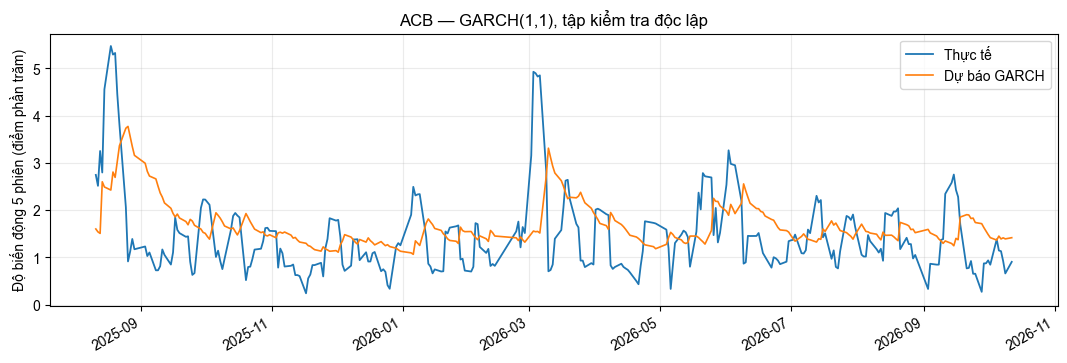

In [4]:
# Dùng font có hỗ trợ ký tự tiếng Việt trong biểu đồ.
plt.rcParams["font.family"] = ["Arial", "DejaVu Sans"]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(comparison["date"], comparison["actual_volatility"], label="Thực tế", linewidth=1.3)
ax.plot(comparison["date"], comparison["predicted_volatility"], label="Dự báo GARCH", linewidth=1.2)
ax.set(title=f"{ticker} — GARCH(1,1), tập kiểm tra độc lập", ylabel="Độ biến động 5 phiên (điểm phần trăm)")
ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); plt.show()


## Diễn giải kết quả

Dự báo ước lượng quy mô biến động của lợi suất trong ngắn hạn; đây không phải xác suất thua lỗ. Trung bình phương sai có điều kiện nhiều bước của GARCH và độ lệch chuẩn mẫu của năm lợi suất thực tế có liên quan nhưng không phải cùng một đại lượng. Dùng các chỉ số trên tập kiểm tra theo thời gian làm điểm đánh giá cuối cùng cho mô hình cơ sở.